In [2]:

from google.colab import files
uploaded = files.upload()


Saving archive.zip to archive.zip


In [3]:

import zipfile
import pandas as pd

z = zipfile.ZipFile("archive.zip")

print(z.namelist())


['household_power_consumption.txt']


In [4]:

df = pd.read_csv(
    z.open("household_power_consumption.txt"),
    sep=";",
    na_values="?",
    nrows=10000
)

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nFirst 5 records:")
display(df.head())


Dataset shape: (10000, 9)

Columns:
['Date', 'Time', 'Global_active_power', 'Global_reactive_power', 'Voltage', 'Global_intensity', 'Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3']

Missing values:
Date                     0
Time                     0
Global_active_power      2
Global_reactive_power    2
Voltage                  2
Global_intensity         2
Sub_metering_1           2
Sub_metering_2           2
Sub_metering_3           2
dtype: int64

First 5 records:


,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
3,16/12/2006,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
4,16/12/2006,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


In [5]:

df.iloc[:, 2:] = df.iloc[:, 2:].interpolate(
    method="linear"
).ffill().bfill()

print("Missing values after handling:")
print(df.isnull().sum())

print("\nTotal missing values:", df.isnull().sum().sum())


Missing values after handling:
Date                     0
Time                     0
Global_active_power      0
Global_reactive_power    0
Voltage                  0
Global_intensity         0
Sub_metering_1           0
Sub_metering_2           0
Sub_metering_3           0
dtype: int64

Total missing values: 0


In [6]:

df["DateTime"] = pd.to_datetime(
    df["Date"] + " " + df["Time"],
    dayfirst=True
)

df = df.sort_values("DateTime").reset_index(drop=True)

print(df[["DateTime", "Global_active_power"]].head())
print("\nTotal records:", len(df))
print("Time interval:")
print(df["DateTime"].diff().value_counts().head())



             DateTime  Global_active_power
0 2006-12-16 17:24:00                4.216
1 2006-12-16 17:25:00                5.360
2 2006-12-16 17:26:00                5.374
3 2006-12-16 17:27:00                5.388
4 2006-12-16 17:28:00                3.666

Total records: 10000
Time interval:
DateTime
0 days 00:01:00    9999
Name: count, dtype: int64


In [8]:

from sklearn.preprocessing import MinMaxScaler

cols = [
    "Global_active_power",
    "Global_reactive_power",
    "Voltage",
    "Global_intensity",
    "Sub_metering_1",
    "Sub_metering_2",
    "Sub_metering_3"
]

split = int(len(df) * 0.8)

scaler = MinMaxScaler()
scaler.fit(df[cols].iloc[:split])

scaled = scaler.transform(df[cols])

print("Normalized data shape:", scaled.shape)
print("Minimum value:", scaled.min())
print("Maximum value:", scaled.max())


Normalized data shape: (10000, 7)
Minimum value: 0.0
Maximum value: 1.052325581395349


In [9]:

import numpy as np

t = 60
target = cols.index("Global_active_power")

X_train, y_train = [], []
X_test, y_test = [], []

for i in range(t, split):
    X_train.append(scaled[i-t:i])
    y_train.append(scaled[i, target])

for i in range(split, len(scaled)):
    X_test.append(scaled[i-t:i])
    y_test.append(scaled[i, target])

X_train = np.array(X_train)
y_train = np.array(y_train)

X_test = np.array(X_test)
y_test = np.array(y_test)

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)


X_train: (7940, 60, 7)
y_train: (7940,)
X_test: (2000, 60, 7)
y_test: (2000,)


In [10]:

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

tf.random.set_seed(42)

model = Sequential([
    tf.keras.Input(shape=(60, 7)),
    LSTM(32, return_sequences=True),
    Dropout(0.2),
    LSTM(16),
    Dense(1)
])

model.compile(
    optimizer="adam",
    loss="mse"
)

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 60, 32)         │         5,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 60, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 16)             │         3,136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,273 (32.32 KB)

 Trainable params: 8,273 (32.32 KB)

 Non-trainable params: 0 (0.00 B)

In [11]:

history = model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.1,
    shuffle=False,
    verbose=1
)


Epoch 1/10
112/112 ━━━━━━━━━━━━━━━━━━━━ 9s 48ms/step - loss: 0.0193 - val_loss: 0.0038
Epoch 2/10
112/112 ━━━━━━━━━━━━━━━━━━━━ 6s 50ms/step - loss: 0.0075 - val_loss: 0.0036
Epoch 3/10
112/112 ━━━━━━━━━━━━━━━━━━━━ 6s 51ms/step - loss: 0.0062 - val_loss: 0.0030
Epoch 4/10
112/112 ━━━━━━━━━━━━━━━━━━━━ 5s 45ms/step - loss: 0.0055 - val_loss: 0.0026
Epoch 5/10
112/112 ━━━━━━━━━━━━━━━━━━━━ 6s 56ms/step - loss: 0.0053 - val_loss: 0.0023
Epoch 6/10
112/112 ━━━━━━━━━━━━━━━━━━━━ 5s 44ms/step - loss: 0.0050 - val_loss: 0.0022
Epoch 7/10
112/112 ━━━━━━━━━━━━━━━━━━━━ 7s 57ms/step - loss: 0.0047 - val_loss: 0.0022
Epoch 8/10
112/112 ━━━━━━━━━━━━━━━━━━━━ 9s 44ms/step - loss: 0.0047 - val_loss: 0.0021
Epoch 9/10
112/112 ━━━━━━━━━━━━━━━━━━━━ 6s 56ms/step - loss: 0.0046 - val_loss: 0.0019
Epoch 10/10
112/112 ━━━━━━━━━━━━━━━━━━━━ 5s 45ms/step - loss: 0.0045 - val_loss: 0.0018


In [12]:

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

pred = model.predict(X_test, verbose=0)

actual = scaler.inverse_transform(
    np.column_stack([
        np.zeros((len(y_test), target)),
        y_test,
        np.zeros((len(y_test), len(cols)-target-1))
    ])
)[:, target]

predicted = scaler.inverse_transform(
    np.column_stack([
        np.zeros((len(pred), target)),
        pred.ravel(),
        np.zeros((len(pred), len(cols)-target-1))
    ])
)[:, target]

mae = mean_absolute_error(actual, predicted)
rmse = np.sqrt(mean_squared_error(actual, predicted))

print("MAE:", round(mae, 4), "kW")
print("RMSE:", round(rmse, 4), "kW")


MAE: 0.5742 kW
RMSE: 0.7686 kW


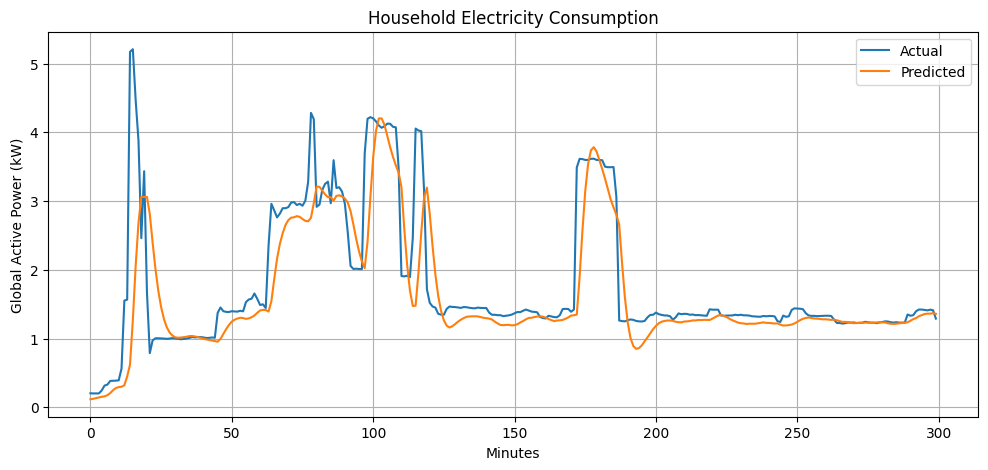

In [15]:

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plt.plot(actual[:300], label="Actual")
plt.plot(predicted[:300], label="Predicted")
plt.title("Household Electricity Consumption")
plt.xlabel("Minutes")
plt.ylabel("Global Active Power (kW)")
plt.legend()
plt.grid(True)
plt.show()


In [16]:

print("Unseen Test Records - First 10")

for i in range(10):
    print(
        f"Actual: {actual[i]:.3f} kW | "
        f"Predicted: {predicted[i]:.3f} kW"
    )

print("\nFinal Evaluation")
print("MAE:", round(mae, 4), "kW")
print("RMSE:", round(rmse, 4), "kW")


Unseen Test Records - First 10
Actual: 0.204 kW | Predicted: 0.118 kW
Actual: 0.202 kW | Predicted: 0.124 kW
Actual: 0.202 kW | Predicted: 0.134 kW
Actual: 0.202 kW | Predicted: 0.145 kW
Actual: 0.246 kW | Predicted: 0.153 kW
Actual: 0.316 kW | Predicted: 0.160 kW
Actual: 0.330 kW | Predicted: 0.177 kW
Actual: 0.384 kW | Predicted: 0.207 kW
Actual: 0.386 kW | Predicted: 0.249 kW
Actual: 0.388 kW | Predicted: 0.280 kW

Final Evaluation
MAE: 0.5742 kW
RMSE: 0.7686 kW



# Household Electricity Consumption Forecasting using LSTM

## Objective
Predict future household electricity consumption using historical minute-level measurements.

## Dataset
Household Electric Power Consumption — Kaggle.

## Model
Long Short-Term Memory (LSTM), a recurrent neural network for sequential data.

## Workflow
1. Load 10,000 records
2. Handle missing values
3. Normalize numerical features
4. Generate 60-minute sequences
5. Train the LSTM model
6. Evaluate using MAE and RMSE
7. Plot actual versus predicted consumption
8. Test predictions on unseen records

## Results
- MAE: 0.5742 kW
- RMSE: 0.7686 kW
